<a href="https://colab.research.google.com/github/ahmed-abo-el3ela/assymint-of-data-science-code/blob/main/s17_AMIT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans

In [ ]:
from sklearn.datasets import make_blobs
X, _ = make_blobs( n_features=3,n_samples=1000,    centers=3, cluster_std=1.5, random_state=42)

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


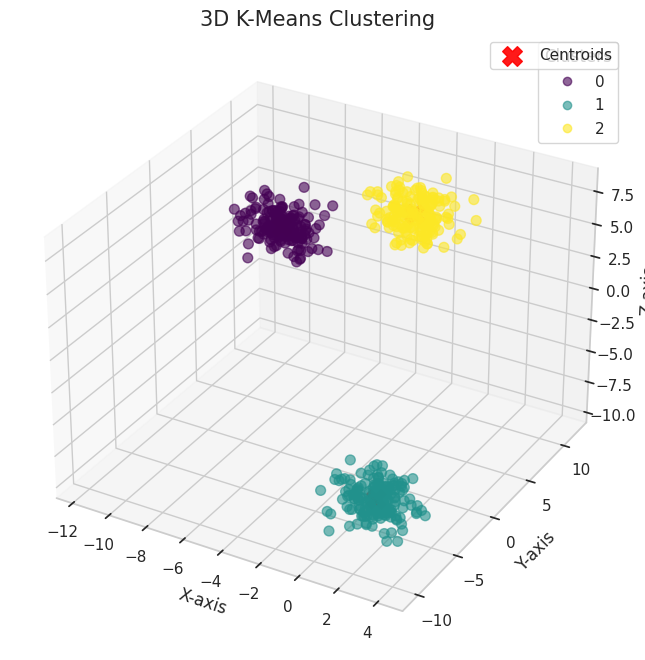

Cluster Centers:
[[-8.97400718  7.36235491  2.12383033]
 [ 1.91713324 -6.91348279 -6.8626939 ]
 [-2.53380896  9.1292391   4.75578179]]


In [ ]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Step 1: Generate Synthetic 3D Data
n_samples = 500
n_features = 3
n_clusters = 3

X, y_true = make_blobs(n_samples=n_samples,
                       n_features=n_features,
                       centers=n_clusters,
                       cluster_std=1.0,
                       random_state=42)

# Step 2: Apply K-Means Clustering
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)
centers = kmeans.cluster_centers_

# Step 3: Visualize the Clusters
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(X[:, 0], X[:, 1], X[:, 2],
                     c=y_kmeans, cmap='viridis', s=50, alpha=0.6)
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2],
           c='red', s=200, alpha=0.9, marker='X', label='Centroids')

ax.set_title('3D K-Means Clustering', fontsize=15)
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Z-axis')

legend1 = ax.legend(*scatter.legend_elements(),
                    title="Clusters")
ax.add_artist(legend1)
ax.legend()
plt.show()

# Step 4: Print Cluster Centers
print("Cluster Centers:")
print(centers)

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import plotly.graph_objects as go

# ============================
# Step 1: Data Preparation
# ============================

# Generate synthetic 3D data
n_samples = 500
n_clusters = 3
X, y_true = make_blobs(n_samples=n_samples, n_features=3, centers=n_clusters, cluster_std=1.0, random_state=42)

# ============================
# Step 2: Apply K-Means Clustering
# ============================

kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)
centers = kmeans.cluster_centers_

# ============================
# Step 3: Plotting the Results with Plotly
# ============================

# Create a 3D scatter plot
fig = go.Figure()

# Add the clustered data points
fig.add_trace(go.Scatter3d(
    x=X[:, 0],  # X-axis values
    y=X[:, 1],  # Y-axis values
    z=X[:, 2],  # Z-axis values
    mode='markers',
    marker=dict(
        size=5,
        color=y_kmeans,  # Color by cluster
        colorscale='Viridis',  # Color scale
        opacity=0.8
    ),
    name='Clustered Points'
))

# Add the centroids as larger red markers
fig.add_trace(go.Scatter3d(
    x=centers[:, 0],  # X-axis centroid
    y=centers[:, 1],  # Y-axis centroid
    z=centers[:, 2],  # Z-axis centroid
    mode='markers',
    marker=dict(
        size=10,
        color='red',  # Red color for centroids
        symbol='x'
    ),
    name='Cluster Centroids'
))

# Customize the layout
fig.update_layout(
    scene=dict(
        xaxis_title='X-axis',
        yaxis_title='Y-axis',
        zaxis_title='Z-axis'
    ),
    title="3D K-Means Clustering Visualization",
    showlegend=True
)

# Show the interactive plot
fig.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



In [ ]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import plotly.graph_objs as go
import plotly.io as pio

# Step 1: Generate the dataset
X, _ = make_blobs(n_features=3, n_samples=1000, centers=3, cluster_std=1.5, random_state=42)

# Step 2: Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(X)

# Step 3: Calculate the Silhouette score
sil_score = silhouette_score(X, labels)
silhouette_vals = silhouette_samples(X, labels)

# Step 4: 3D Plot of K-Means Clustering using Plotly
centers = kmeans.cluster_centers_  # Get cluster centers

# Create 3D scatter plot for data points
scatter_points = go.Scatter3d(
    x=X[:, 0], y=X[:, 1], z=X[:, 2],
    mode='markers',
    marker=dict(
        size=5,
        color=labels,  # Color points by their cluster label
        colorscale='Viridis',
        opacity=0.8
    ),
    name="Data Points"
)

# Create 3D scatter plot for cluster centers
scatter_centers = go.Scatter3d(
    x=centers[:, 0], y=centers[:, 1], z=centers[:, 2],
    mode='markers',
    marker=dict(
        size=10,
        color='red',
        symbol='x',
        opacity=1
    ),
    name="Cluster Centers"
)

# Define layout for the 3D scatter plot
layout_3d = go.Layout(
    title=f"3D K-Means Clustering (n_clusters=3, Silhouette Score: {sil_score:.4f})",
    scene=dict(
        xaxis_title="Feature 1",
        yaxis_title="Feature 2",
        zaxis_title="Feature 3"
    ),
    showlegend=True
)

# Create figure and display
fig_3d = go.Figure(data=[scatter_points, scatter_centers], layout=layout_3d)
pio.show(fig_3d)

# Step 5: Visualize the Silhouette Scores for each cluster
fig_silhouette = go.Figure()

# Add bars for each sample's silhouette score
for i in range(3):  # Loop over each cluster
    cluster_silhouette_vals = silhouette_vals[labels == i]
    cluster_silhouette_vals.sort()  # Sort the values for better visualization
    y_ticks = np.arange(len(cluster_silhouette_vals))

    fig_silhouette.add_trace(go.Bar(
        x=cluster_silhouette_vals,
        y=y_ticks,
        orientation='h',  # Horizontal bars
        name=f'Cluster {i}',
        marker=dict(color=cluster_silhouette_vals, colorscale='Viridis'),
        showlegend=True
    ))

# Add average silhouette score as a vertical line
fig_silhouette.add_shape(
    type="line",
    x0=sil_score,
    y0=0,
    x1=sil_score,
    y1=1000,
    line=dict(color="Red", width=2, dash="dash"),
    name="Average Silhouette Score"
)

# Update layout for the Silhouette plot
fig_silhouette.update_layout(
    title=f'Silhouette Scores for K-Means Clustering (Average: {sil_score:.4f})',
    xaxis_title="Silhouette Coefficient",
    yaxis_title="Samples",
    showlegend=True
)

# Show Silhouette plot
pio.show(fig_silhouette)


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



In [ ]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Step 1: Generate the dataset
X, y = make_blobs(n_features=3, n_samples=1000, centers=3, cluster_std=1.5, random_state=42)

# Step 2: Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)

# Predict the cluster labels
labels = kmeans.predict(X)

# Step 3: Calculate the silhouette score
sil_score = silhouette_score(X, labels)

# Print the silhouette score
print(f'Silhouette Score: {sil_score:.4f}')


Silhouette Score: 0.6493


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



In [ ]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Step 1: Generate the blob dataset (unsupervised learning)
X, y = make_blobs(n_features=3, n_samples=1000, centers=3, cluster_std=1.5, random_state=42)

# Step 2: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Apply K-Means clustering on the training data
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_train)

# Predict the cluster labels for training and testing data
train_clusters = kmeans.predict(X_train)
test_clusters = kmeans.predict(X_test)

# Step 4: Use the cluster labels as features
# Combine the original features with the cluster labels
X_train_with_clusters = np.column_stack((X_train, train_clusters))
X_test_with_clusters = np.column_stack((X_test, test_clusters))

# Step 5: Train a supervised learning model (e.g., logistic regression) using the combined features
model = LogisticRegression()
model.fit(X_train_with_clusters, y_train)

# Step 6: Make predictions and evaluate the model
y_pred = model.predict(X_test_with_clusters)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy of the model using K-Means clusters as features: {accuracy:.2f}")


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Accuracy of the model using K-Means clusters as features: 0.99
